# ML Pipeline Formative 1: Task 1 - EDA
## Part A: Understanding The Dataset

Author: Patrick Tuyizere

The `Metro Interstate Traffic Volume` dataset from kaggle contains hourly traffic volume for the interstate 94 westbound at Minneapolis, St-Paul, Minnesota together with local weather conditions.

- **Time Rage**: The dataset begins on October 2, 2012 at 09:00:00 and concludes on September 30, 2018 at 23:00:00 (accounting for approximately 6 years of observations).
- **Frequency**: The dataset contains 48,204 rows recorded an an hourly frequency. Analysing the timestamps reveals that due to sensor mulfunctions, there are non continous time gaps that exist in the dataset.
- **Target Variable**: `traffic_volume` This a a continous integer that that measures the number of vehicles passing the sensor in an hour.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


# Search the current directory and its parents for the repository dataset.
dataset_filename = Path(
    "data/raw/Metro_Interstate_Traffic_Volume.csv"
)

repository_root = None

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / dataset_filename).exists():
        repository_root = candidate
        break

if repository_root is None:
    raise FileNotFoundError(
        "Could not find data/raw/Metro_Interstate_Traffic_Volume.csv. "
        "Clone or pull the complete repository before running this notebook."
    )

dataset_path = repository_root / dataset_filename

df = pd.read_csv(dataset_path)

df["date_time"] = pd.to_datetime(df["date_time"])
df = df.sort_values("date_time").reset_index(drop=True)

print(f"Repository root: {repository_root}")
print(f"Dataset path:    {dataset_path}")
print(f"Start date:      {df['date_time'].min()}")
print(f"End date:        {df['date_time'].max()}")
print(f"Total rows:      {len(df):,}")



Repository root: c:\Users\AKINLOYE\Documents\machine_learning_pipeline_formative-one
Dataset path:    c:\Users\AKINLOYE\Documents\machine_learning_pipeline_formative-one\data\raw\Metro_Interstate_Traffic_Volume.csv
Start date:      2012-10-02 09:00:00
End date:        2018-09-30 23:00:00
Total rows:      48,204


### Missing Values, Gaps, and Outlier Handling

When we run `df.isnull().sum()`, we see that there are no missing values in the raw CSV. Pandas simply treats the "None" string found in the holiday column as a missing value indicator but that doesn't mean that the values are missing. We handle this quirk later. Time series data has 2 data quality issues that require handling:
1. **Duplicate Timestamps**: Multiple weather descriptions recorded in the same hour (e.g: both "Rain" and "Mist") produce duplicate hourly timestamps.
2. **Missing Hourly Time Intervals**: Given a time period spanning 6 years from 2012 to 2018. There should be around 52,560 hourly intervals but there is only around 48,204.
3. **Sensor Outliers**: The `temp` column contains values recorded as 0.0 Kelvin ($-273.15 C), which is physically impossible and indicates sensor failure. Also `rain_1h` contains spikes exceeding 9,000 mm.

### Preprocessing Strategy
- **Removing duplicates**: We put together multiple readings per hour by taking the mean of numerical variables and the most severe of categorical weather.
- **Fixing the indexes**: We also reindex the dataset into a complete, uninterrupted hourly format.
- **Imputation**: Missing temperature and weather features are imputed using linear interpolation (`df.interpolate(method='time')`). The Target variable `traffic_volume` missing values are also imputed using forward-fill (`ffill`) followed by backward-fill (`bfill`), or historical median by hour-of-week and sensor anomalies (`temp == 0 or rain_1h > 500`) are flagged as NaN before interpolation.

In [2]:
# 1. Handle the holiday column
print("----- Issue 1: Null Check and Holiday Inspection -----")
print(df.isnull().sum())

print("\nUnique values in 'holiday':")
print(df["holiday"].value_counts(dropna=False).head())

# Pandas may interpret the text "None" as a missing value.
# Both forms mean that the hour is not a holiday.
df["holiday"] = df["holiday"].fillna("None")
df["is_holiday"] = (df["holiday"] != "None").astype(int)


# 2. Detect and remove sensor faults BEFORE creating df_hourly
print("\n----- Issue 2: Sensor Malfunctions -----")

temp_outliers = df[df["temp"] < 100]
rain_outliers = df[df["rain_1h"] > 500]

print(f"Rows with impossible temperatures: {len(temp_outliers)}")
print(temp_outliers[["date_time", "temp", "traffic_volume"]].head())

print(f"\nRows with impossible rainfall: {len(rain_outliers)}")
print(rain_outliers[["date_time", "rain_1h", "traffic_volume"]].head())

# Convert physically impossible sensor values to missing values.
# This must happen before aggregation into df_hourly.
df["temp"] = df["temp"].mask(df["temp"] < 100)
df["rain_1h"] = df["rain_1h"].mask(df["rain_1h"] > 500)


# 3. Combine multiple weather readings recorded at the same timestamp
print("\n----- Issue 3: Duplicate Timestamps -----")

duplicate_timestamp_rows = df.duplicated(subset=["date_time"]).sum()
print(f"Number of duplicate timestamp rows: {duplicate_timestamp_rows}")

df_hourly = (
    df.groupby("date_time", as_index=False)
    .mean(numeric_only=True)
)


# 4. Detect missing hourly intervals
print("\n----- Issue 4: Missing Hourly Intervals -----")

unique_times = (
    df["date_time"]
    .drop_duplicates()
    .sort_values()
)

time_diffs = unique_times.diff()

print("Largest gaps between consecutive observations:")
print(time_diffs.sort_values(ascending=False).head())

expected_hours = len(
    pd.date_range(
        start=df["date_time"].min(),
        end=df["date_time"].max(),
        freq="h",
    )
)

actual_unique_hours = df["date_time"].nunique()
missing_hours = expected_hours - actual_unique_hours

print(f"Expected hourly slots: {expected_hours}")
print(f"Observed hourly slots: {actual_unique_hours}")
print(f"Missing hourly slots:  {missing_hours}")


# 5. Create a complete hourly timeline
df_hourly = df_hourly.set_index("date_time").sort_index()

full_timeline = pd.date_range(
    start=df_hourly.index.min(),
    end=df_hourly.index.max(),
    freq="h",
)

df_clean = df_hourly.reindex(full_timeline)
df_clean.index.name = "date_time"


# 6. Impute missing values
# Temperature and cloud cover change continuously, so interpolate them.
df_clean["temp"] = df_clean["temp"].interpolate(
    method="time",
    limit_direction="both",
)

df_clean["clouds_all"] = df_clean["clouds_all"].interpolate(
    method="time",
    limit_direction="both",
)

# Missing rain and snow mean that no precipitation was reported.
df_clean["rain_1h"] = df_clean["rain_1h"].fillna(0.0)
df_clean["snow_1h"] = df_clean["snow_1h"].fillna(0.0)

# Fill missing traffic hours using the last available observation.
df_clean["traffic_volume"] = (
    df_clean["traffic_volume"]
    .ffill()
    .bfill()
)

df_clean["is_holiday"] = (
    df_clean["is_holiday"]
    .fillna(0)
    .astype(int)
)


# 7. Validate the cleaning result
assert not (df_clean["temp"] < 100).any(), \
    "Impossible temperature values remain."

assert not (df_clean["rain_1h"] > 500).any(), \
    "Impossible rainfall values remain."

print(f"\nFinal cleaned dataset shape: {df_clean.shape}")
print("\nRemaining missing values:")
print(df_clean.isnull().sum())

print("\nSensor-fault verification:")
print("Temperatures below 100 K:", (df_clean["temp"] < 100).sum())
print("Rainfall above 500 mm:", (df_clean["rain_1h"] > 500).sum())

----- Issue 1: Null Check and Holiday Inspection -----
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
dtype: int64

Unique values in 'holiday':
holiday
NaN                 48143
Labor Day               7
Thanksgiving Day        6
Christmas Day           6
New Years Day           6
Name: count, dtype: int64

----- Issue 2: Sensor Malfunctions -----
Rows with impossible temperatures: 10
                date_time  temp  traffic_volume
11898 2014-01-31 03:00:00   0.0             361
11899 2014-01-31 04:00:00   0.0             734
11900 2014-01-31 05:00:00   0.0            2557
11901 2014-01-31 06:00:00   0.0            5150
11946 2014-02-02 03:00:00   0.0             291

Rows with impossible rainfall: 1
                date_time  rain_1h  traffic_volume
24872 2016-07-11 17:00:00

In [3]:
summary_stats = df_clean.describe().round(2)
print(summary_stats)
df_clean.head()

           temp   rain_1h   snow_1h  clouds_all  traffic_volume  is_holiday
count  52551.00  52551.00  52551.00    52551.00        52551.00    52551.00
mean     282.55      0.06      0.00       44.52         2900.77        0.00
std       12.40      0.68      0.00       36.93         2083.16        0.03
min      243.39      0.00      0.00        0.00            0.00        0.00
25%      273.58      0.00      0.00        1.00          551.00        0.00
50%      286.42      0.00      0.00       40.00         2883.00        0.00
75%      291.70      0.00      0.00       89.00         4790.00        0.00
max      310.07     55.63      0.51      100.00         7280.00        1.00


,temp,rain_1h,snow_1h,clouds_all,traffic_volume,is_holiday
date_time,,,,,,
2012-10-02 09:00:00,288.28,0.0,0.0,40.0,5545.0,0
2012-10-02 10:00:00,289.36,0.0,0.0,75.0,4516.0,0
2012-10-02 11:00:00,289.58,0.0,0.0,90.0,4767.0,0
2012-10-02 12:00:00,290.13,0.0,0.0,90.0,5026.0,0
2012-10-02 13:00:00,291.14,0.0,0.0,75.0,4918.0,0


## Part B: Analytical Questions

In [4]:
# Feature engineering for analytical questions and forecasting

# Lag features contain only information available before the target hour.
df_clean["lag_1"] = df_clean["traffic_volume"].shift(1)
df_clean["lag_24"] = df_clean["traffic_volume"].shift(24)
df_clean["lag_168"] = df_clean["traffic_volume"].shift(168)

# Shift first so the current target value is excluded.
# At timestamp t, rolling_mean_24 contains traffic from t-24 to t-1.
previous_traffic = df_clean["traffic_volume"].shift(1)

df_clean["rolling_mean_24"] = (
    previous_traffic
    .rolling(window=24, min_periods=24)
    .mean()
)

df_clean["rolling_mean_168"] = (
    previous_traffic
    .rolling(window=168, min_periods=168)
    .mean()
)

# Calendar features
df_clean["hour"] = df_clean.index.hour
df_clean["dayofweek"] = df_clean.index.dayofweek
df_clean["is_weekend"] = (
    df_clean["dayofweek"]
    .isin([5, 6])
    .astype(int)
)

print(
    df_clean[
        [
            "traffic_volume",
            "lag_1",
            "lag_24",
            "lag_168",
            "rolling_mean_24",
            "rolling_mean_168",
        ]
    ].head(170)
)

                     traffic_volume   lag_1  lag_24  lag_168  rolling_mean_24  \
date_time                                                                       
2012-10-02 09:00:00          5545.0     NaN     NaN      NaN              NaN   
2012-10-02 10:00:00          4516.0  5545.0     NaN      NaN              NaN   
2012-10-02 11:00:00          4767.0  4516.0     NaN      NaN              NaN   
2012-10-02 12:00:00          5026.0  4767.0     NaN      NaN              NaN   
2012-10-02 13:00:00          4918.0  5026.0     NaN      NaN              NaN   
...                             ...     ...     ...      ...              ...   
2012-10-09 06:00:00          5733.0  2678.0  5563.0      NaN      3425.416667   
2012-10-09 07:00:00          6449.0  5733.0  6676.0      NaN      3432.500000   
2012-10-09 08:00:00          5765.0  6449.0  5966.0      NaN      3423.041667   
2012-10-09 09:00:00          5599.0  5765.0  4832.0   5545.0      3414.666667   
2012-10-09 10:00:00         

C:\Users\AKINLOYE\AppData\Local\Temp\ipykernel_2888\1377040365.py:26: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df_clean["dayofweek"] = df_clean.index.dayofweek


### Question 1: Does traffic volume have an increasing or decreasing trend over time, and how does a moving average make it easier to see?

On an hourly basis, the traffic volume jumps up and down making it particularly difficult to see long term trends.

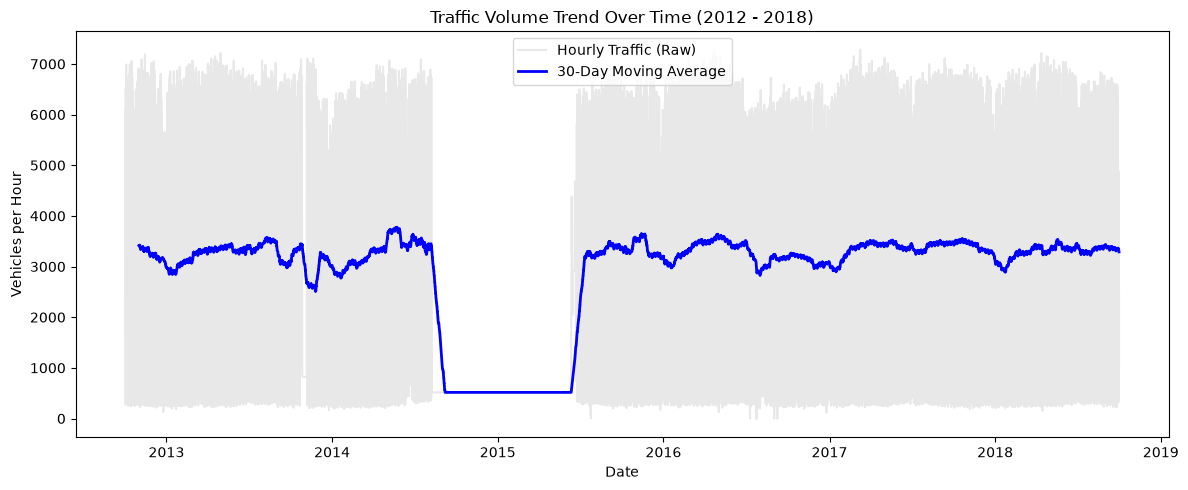

In [5]:
# 1. Calculate a 30-day (720 hours) moving average
df_clean["traffic_30d_ma"] = (df_clean["traffic_volume"].rolling(window=720).mean())

# 2. Plot raw traffic alongside the moving average
plt.figure(figsize=(12, 5))
plt.plot(
    df_clean.index,
    df_clean["traffic_volume"],
    color="lightgray",
    alpha=0.5,
    label="Hourly Traffic (Raw)",
)
plt.plot(
    df_clean.index,
    df_clean["traffic_30d_ma"],
    color="blue",
    linewidth=2,
    label="30-Day Moving Average",
)
plt.title("Traffic Volume Trend Over Time (2012 - 2018)")
plt.xlabel("Date")
plt.ylabel("Vehicles per Hour")
plt.legend()
plt.tight_layout()
plt.show()

The resulting plot shows long term stable, flat trend consistently averaging between 3000 - 3,500 vehicles per hour. The huge deep drop from late 2014 to mid 2015 suggests a major sensor outage and mulfunctions. The blue line shows the 30 day moving average and behid is the gray band showing the day and night spikes. We can also see a fairly consistent drop in traffic volume towards the end of each year most likely cuased by winter cold temperatures.

### Question 2: Are there lag effects where traffic volume right now is related to traffic volume from previous hours?
Usually in time series data, the current value depends on the past values.
I create 2 lag features:
1. **Lag 1**: Traffic 1 hour ago(`shift(1)`)
2. **Lag 24**: Traffic at the exact same hour yesterday (`shift(24)`)

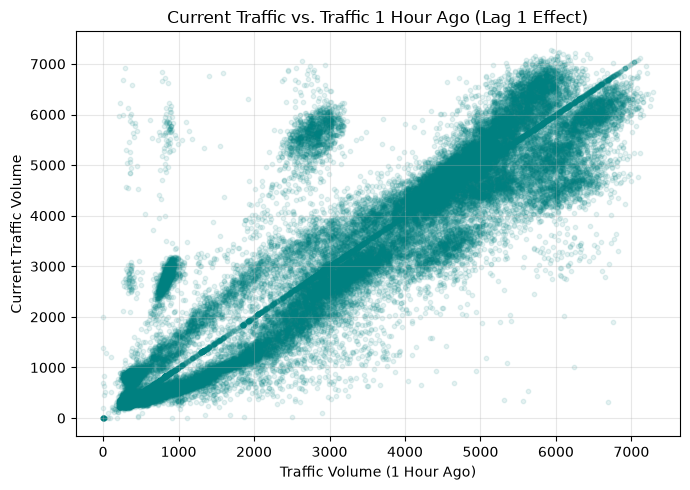

Correlation with 1 hour ago:  0.93
Correlation with 24 hours ago: 0.86


In [6]:
# 1. Create lag features
df_clean["lag_1"] = df_clean["traffic_volume"].shift(1)
df_clean["lag_24"] = df_clean["traffic_volume"].shift(24)

# 2. Scatter plot the current traffic vs traffic 1 hour ago
plt.figure(figsize=(7, 5))
plt.scatter(
    df_clean["lag_1"],
    df_clean["traffic_volume"],
    alpha=0.1,
    color="teal",
    s=10,
)
plt.title("Current Traffic vs. Traffic 1 Hour Ago (Lag 1 Effect)")
plt.xlabel("Traffic Volume (1 Hour Ago)")
plt.ylabel("Current Traffic Volume")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Print correlation values
print(f"Correlation with 1 hour ago:  {df_clean['traffic_volume'].corr(df_clean['lag_1']):.2f}")
print(f"Correlation with 24 hours ago: {df_clean['traffic_volume'].corr(df_clean['lag_24']):.2f}")

The scatter plotting shows a strong correlation between consecutive hours. This means that traffic doesn't jump or fall dramatically from one hour to another. The data concentrates in 2 critical zones. A lower cluster of 500 - 1,000 vehicles (late night and early morning) and a higher cluster of 4,500 - 6,000 vehicles (daytime traffic and rush hours). A key observation is that lag 1 could serve as the perfect baseline so including it as an input feature in any predictive model would allow for good future hour predictions.

### Question 3: Do external weather variables correlate with traffic volume over time?
A common assumption is that bad weather results in reduced traffic volume. We then evaluate correlation between traffic volume and weather variables.

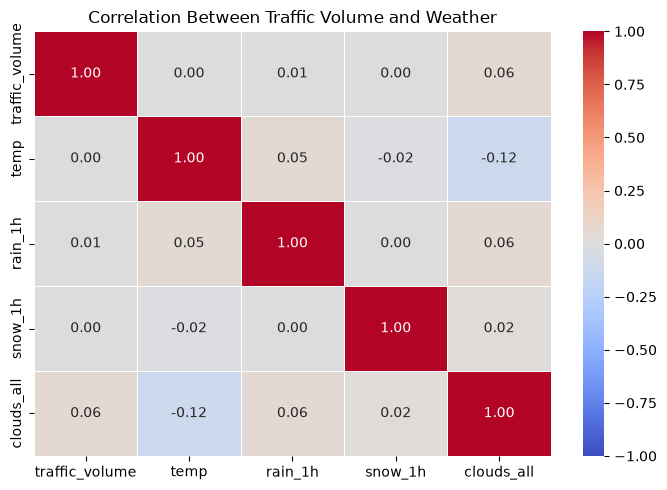

In [7]:
# 1. Select traffic and weather columns
weather_cols = ["traffic_volume", "temp", "rain_1h", "snow_1h", "clouds_all"]
corr_matrix = df_clean[weather_cols].corr()

# 2. Plot correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title("Correlation Between Traffic Volume and Weather")
plt.tight_layout()
plt.show()

The heatmap shows virtually no linear correlation between all weather variables and traffic volume. This is an apparent contradiction with our conclusion that cold winter periods result in a drop in traffic year on year. The reason is because the 24 hourly circle in the dataset introduces hourly noise that masks seasonal trends.

### Question 4: What hours of the day have the highest and lowest traffic volume?
If we calculate the average traffic for every hour of the day (from 0 to 23), we can spot the exact commute peaks.

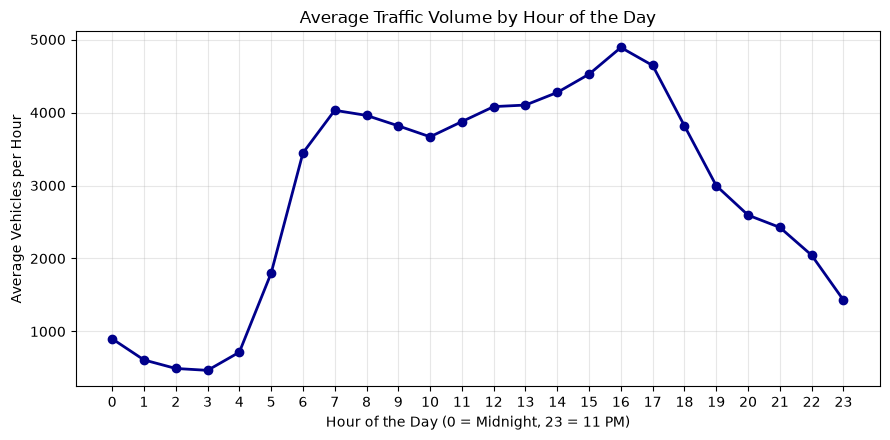

In [8]:
# 1. Group by hour of the day and calculate average traffic
hourly_traffic = df_clean.groupby(df_clean.index.hour)["traffic_volume"].mean()

# 2. Plot hourly line chart
plt.figure(figsize=(9, 4.5))
plt.plot(
    hourly_traffic.index,
    hourly_traffic.values,
    marker="o",
    color="darkblue",
    linewidth=2,
)
plt.title("Average Traffic Volume by Hour of the Day")
plt.xlabel("Hour of the Day (0 = Midnight, 23 = 11 PM)")
plt.ylabel("Average Vehicles per Hour")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The graph shows the typical distribution of traffic volume due to commuting trips throughout the day, the low point of traffic volume occurs between 2:00 AM and 3:00 AM (below 500 vehicles/hour), and there is a sharp increase in traffic volume during morning rush hour until the traffic reaches its first peak of about 4,000 vehicles/hour at 7:00 AM. Maintaining the high volume up until midday, traffic peaks for the second time at 4:00 PM (Hour 16) at a high point of nearly 4,900 vehicles/hour due to the evening commute trip.

### Question 5: How does traffic volume differ between weekdays and weekends?

C:\Users\AKINLOYE\AppData\Local\Temp\ipykernel_2888\255339323.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  day_label = df_clean.index.dayofweek.map(


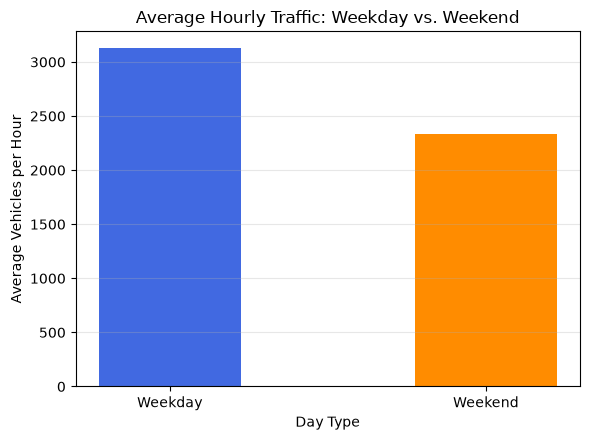

date_time
Weekday    3126.951715
Weekend    2335.817692
Name: traffic_volume, dtype: float64


In [9]:
# 1. Create label: Weekday vs Weekend (5 and 6 are Saturday and Sunday)
day_label = df_clean.index.dayofweek.map(
    lambda x: "Weekend" if x >= 5 else "Weekday"
)
weekday_comparison = df_clean.groupby(day_label)["traffic_volume"].mean()

# 2. Bar plot comparing the two averages
plt.figure(figsize=(6, 4.5))
plt.bar(
    weekday_comparison.index,
    weekday_comparison.values,
    color=["royalblue", "darkorange"],
    width=0.45,
)
plt.title("Average Hourly Traffic: Weekday vs. Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Vehicles per Hour")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(weekday_comparison)

It can be seen that there is a notable increase in the number of cars on weekdays when compared to the weekends. On average, weekdays register over 3,100 cars per hour, while the number drops down to about 2,350 cars per hour during the weekends. This is due to the fact that people travel to work and schools from Monday to Friday, and as a result fewer journeys during the weekend days.

## Part C: Model Training And Experiment Comparison
To predict `traffic_volume`, we chose to use a Random Forest Regressor which should be able to adequately capture non linear interactions and require less feature normalization.

### 1. Train, Test Split
In time-series dataset due to data leakage, we split chronologically:
- **Training Set**: Data before Jan 2018 (around 88%)
- **Test Set**: Data after Jan 2018

In [10]:
# Experiment 1: basic calendar and weather features
feature_cols_basic = [
    "hour",
    "dayofweek",
    "temp",
    "clouds_all",
    "rain_1h",
]

# Experiment 2: calendar, weather, lag and historical rolling features
feature_cols_advanced = [
    "hour",
    "dayofweek",
    "is_weekend",
    "temp",
    "clouds_all",
    "rain_1h",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_24",
]

# Only remove rows that are missing values required by the models.
# Do not let unused columns, such as traffic_30d_ma, remove extra rows.
required_model_columns = list(
    dict.fromkeys(
        feature_cols_basic
        + feature_cols_advanced
        + ["traffic_volume"]
    )
)

model_data = df_clean.dropna(
    subset=required_model_columns
).copy()

# Chronological train-test split
cutoff_date = pd.Timestamp("2018-01-01")

train_df = model_data.loc[
    model_data.index < cutoff_date
].copy()

test_df = model_data.loc[
    model_data.index >= cutoff_date
].copy()

y_train = train_df["traffic_volume"]
y_test = test_df["traffic_volume"]

print("Model dataset verification")
print("--------------------------")
print(f"First model timestamp: {model_data.index.min()}")
print(f"Last model timestamp:  {model_data.index.max()}")
print(f"Training rows:         {len(train_df):,}")
print(f"Testing rows:          {len(test_df):,}")

print("\nMissing training feature values:")
print(train_df[required_model_columns].isnull().sum())

print("\nMissing testing feature values:")
print(test_df[required_model_columns].isnull().sum())

assert not train_df[required_model_columns].isnull().any().any()
assert not test_df[required_model_columns].isnull().any().any()

Model dataset verification
--------------------------
First model timestamp: 2012-10-09 09:00:00
Last model timestamp:  2018-09-30 23:00:00
Training rows:         45,831
Testing rows:          6,552

Missing training feature values:
hour               0
dayofweek          0
temp               0
clouds_all         0
rain_1h            0
is_weekend         0
lag_1              0
lag_24             0
lag_168            0
rolling_mean_24    0
traffic_volume     0
dtype: int64

Missing testing feature values:
hour               0
dayofweek          0
temp               0
clouds_all         0
rain_1h            0
is_weekend         0
lag_1              0
lag_24             0
lag_168            0
rolling_mean_24    0
traffic_volume     0
dtype: int64


### 2. Model Experiments And Hyperparameter Tuning
- **Experiment 1 - Baseline**: Uses basic calendar and weather features (`hour`, `dayofweek`, `temp`, `clouds_all`, `rain_1h`) without lag signals. Trees are constrained to shallow depth (`n_estimators=50`, `max_depth=8`) to prevent overfitting.
- **Experiment 2 - Tuned Autoregressive**: Uses full time series context (`lag_1`, `lag_24`, `lag_168`, `rolling_mean_24`) with deeper tree capacity (`n_estimators=100`, `max_depth=18`, `min_samples_leaf=4`).

In [11]:
# Experiment 1: Baseline Shallow Forest (No Lags)
X_train_exp1 = train_df[feature_cols_basic]
X_test_exp1 = test_df[feature_cols_basic]

exp1_model = RandomForestRegressor(
    n_estimators=50, max_depth=8, random_state=42, n_jobs=-1
)
exp1_model.fit(X_train_exp1, y_train)
y_pred_exp1 = exp1_model.predict(X_test_exp1)

# Experiment 2: Tuned Deep Forest with Lags and Rolling Averages
X_train_exp2 = train_df[feature_cols_advanced]
X_test_exp2 = test_df[feature_cols_advanced]

exp2_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=18,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1,
)
exp2_model.fit(X_train_exp2, y_train)
y_pred_exp2 = exp2_model.predict(X_test_exp2)


# Function to calculate performance metrics
def get_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return round(mae, 2), round(rmse, 2), round(r2, 4)


mae_1, rmse_1, r2_1 = get_metrics(y_test, y_pred_exp1)
mae_2, rmse_2, r2_2 = get_metrics(y_test, y_pred_exp2)

# Print results
comparison_df = pd.DataFrame(
    {
        "Metric": [
            "MAE (Vehicles)",
            "RMSE (Vehicles)",
            "R² Score",
        ],
        "Experiment 1 (Baseline)": [mae_1, rmse_1, r2_1],
        "Experiment 2 (Tuned + Lags)": [mae_2, rmse_2, r2_2],
    }
)

print("\nComparison Summary Table:")
print(comparison_df.to_string(index=False))


Comparison Summary Table:
         Metric  Experiment 1 (Baseline)  Experiment 2 (Tuned + Lags)
 MAE (Vehicles)                 438.7700                     156.6200
RMSE (Vehicles)                 803.6800                     241.6600
       R² Score                   0.8347                       0.9851


Experiment 2 performed substantially better than the baseline experiment. Adding lagged traffic values and a rolling average calculated exclusively from earlier hours reduced MAE from 438.77 to 156.62 vehicles per hour, a reduction of approximately 64%. RMSE decreased from 803.68 to 241.66, while R² increased from 0.8347 to 0.9851. Because the rolling average now excludes the target hour, these results avoid the target leakage present in the earlier implementation.

### 3. Save The Best Model

In [12]:
from pathlib import Path

# Locate the repository root whether the notebook is run from the
# repository root or from the task1_eda_ml directory.
current_directory = Path.cwd()

if (
    (current_directory / "task1_eda_ml").is_dir()
    and (current_directory / "data").is_dir()
):
    repository_root = current_directory
elif (
    current_directory.name == "task1_eda_ml"
    and (current_directory.parent / "data").is_dir()
):
    repository_root = current_directory.parent
else:
    raise RuntimeError(
        "Repository root could not be located. "
        "Run the notebook from the repository or task1_eda_ml directory."
    )

model_path = (
    repository_root
    / "task1_eda_ml"
    / "traffic_forecasting_model.pkl"
)

joblib.dump(exp2_model, model_path)

print(f"Corrected model saved to:\n{model_path}")

Corrected model saved to:
c:\Users\AKINLOYE\Documents\machine_learning_pipeline_formative-one\task1_eda_ml\traffic_forecasting_model.pkl


### 4. Save Processed Data

In [13]:
from pathlib import Path

current_directory = Path.cwd()

if (
    (current_directory / "task1_eda_ml").is_dir()
    and (current_directory / "data").is_dir()
):
    repository_root = current_directory
elif (
    current_directory.name == "task1_eda_ml"
    and (current_directory.parent / "data").is_dir()
):
    repository_root = current_directory.parent
else:
    raise RuntimeError(
        "Repository root could not be located."
    )

processed_data_path = (
    repository_root
    / "data"
    / "processed"
    / "metro_traffic_clean.csv"
)

processed_data_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

export_df = df_clean.reset_index()
export_df.to_csv(processed_data_path, index=False)

print(f"Saved {len(export_df):,} processed rows to:")
print(processed_data_path)

Saved 52,551 processed rows to:
c:\Users\AKINLOYE\Documents\machine_learning_pipeline_formative-one\data\processed\metro_traffic_clean.csv
